# 2장 풀 기반 능동 학습 루프

5단계 루프를 구현하고 무작위 샘플링(Random) 기준선을 확정한다. 여기서 정의한 `query_fn`, `oracle_fn`, `run_loop` 의 모양은 책 끝까지 바뀌지 않는다.

- 2.1 5단계 루프의 구조
- 2.2 TF-IDF와 로지스틱 회귀 학생 모델
- 2.3 시뮬레이션 오라클
- 2.4 질의 함수와 오라클 함수의 표준 인터페이스
- 2.5 무작위 샘플링(Random) 기준선
- 2.6 초기 라벨 크기와 질의 배치 크기의 영향

1장 노트북이 만든 `data/*.csv` 를 읽는다. CPU만으로 돈다.

In [1]:
# ── 환경 설정과 상수 ────
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import koreanize_matplotlib
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score

SEEDS = [0, 1, 2, 3, 4]
N_INIT, K, BUDGET = 100, 50, 2000
ACCENT, INK, GRAY, GRAY2 = "#E32C24", "#1C1C1A", "#575753", "#8C8A85"
LABEL = {"acc": "정확도", "f1": "매크로 F1"}

## 2.2 TF-IDF와 로지스틱 회귀 학생 모델

형태소 분석기 없이 한국어를 다루려고 단어 경계 안의 문자 2~4그램을 쓴다. 벡터라이저는 풀 전체 텍스트로 한 번 적합한다. 라벨을 쓰지 않으므로 정보 누수가 아니다.

In [2]:
# ── 데이터 읽기와 특징 추출 ────
def load_data(name):
    pool = pd.read_csv(f"data/{name}_pool.csv")
    test = pd.read_csv(f"data/{name}_test.csv")
    vec = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 4), min_df=2,
                          max_features=50000, sublinear_tf=True)
    X_pool = vec.fit_transform(pool.text)          # 라벨을 쓰지 않으므로 누수가 아니다
    return dict(name=name, texts=pool.text.values, X_pool=X_pool, y_pool=pool.label.values,
                X_test=vec.transform(test.text), y_test=test.label.values,
                n_classes=pool.label.nunique())

DATA = {name: load_data(name) for name in ("nsmc", "ynat")}
for d in DATA.values():
    print(d["name"], "풀", d["X_pool"].shape, "시험", d["X_test"].shape, "클래스", d["n_classes"])

nsmc 풀 (20000, 50000) 시험 (10000, 50000) 클래스 2
ynat 풀 (20000, 50000) 시험 (9107, 50000) 클래스 7


In [3]:
# ── 학생 모델 ────
def train_model(X, y, seed):
    return LogisticRegression(C=10.0, max_iter=1000, random_state=seed).fit(X, y)

def proba(model, X, n_classes):
    # 라벨 집합에 없는 클래스의 확률 열을 0으로 채워 열 수를 고정한다
    P = np.zeros((X.shape[0], n_classes))
    P[:, model.classes_] = model.predict_proba(X)
    return P

## 2.3 시뮬레이션 오라클

데이터셋의 정답 라벨을 사람 라벨러 대신 돌려준다. 반환값은 (라벨, 신뢰도) 쌍이고 시뮬레이션 오라클의 신뢰도는 늘 1.0이다.

In [4]:
# ── 시뮬레이션 오라클 ────
def make_sim_oracle(y_true):
    # 정답 라벨과 신뢰도 1.0을 돌려준다. 13장의 Jev 오라클이 같은 자리에 들어온다
    return lambda idx, texts: (y_true[idx], np.ones(len(idx)))

## 2.4 질의 함수와 오라클 함수의 표준 인터페이스

```
query_fn(model, data, idx_l, y_l, idx_u, k, rng) -> 고를 풀 인덱스 k개
oracle_fn(idx, texts) -> (라벨, 신뢰도)
run_loop(query_fn, oracle_fn, data, seed) -> (라운드 기록 DataFrame, 라벨 순서 인덱스)
```

질의 함수가 학생 모델뿐 아니라 라벨 집합(idx_l, y_l)까지 받는 이유는 4장 위원회 질의와 5장 기대 오차 감소가 라벨 집합으로 모델을 새로 학습하기 때문이다. 루프 본문은 train → predict → query → label → update 순서를 장마다 같은 모양으로 유지한다.

In [5]:
# ── 능동 학습 루프 ────
def run_loop(query_fn, oracle_fn, data, seed, n_init=N_INIT, k=K, budget=BUDGET):
    rng = np.random.default_rng(seed)
    n = data["X_pool"].shape[0]
    idx_l = rng.choice(n, n_init, replace=False)
    y_l, _ = oracle_fn(idx_l, data["texts"][idx_l])
    idx_u = np.setdiff1d(np.arange(n), idx_l)
    log = []
    while True:
        model = train_model(data["X_pool"][idx_l], y_l, seed)                          # 1. train
        y_hat = model.predict(data["X_test"])                                             # 평가
        log.append(dict(seed=seed, n_labeled=len(idx_l), acc=accuracy_score(data["y_test"], y_hat),
                        f1=f1_score(data["y_test"], y_hat, average="macro"), t_query=np.nan))
        if len(idx_l) >= budget:
            break
        t0 = time.perf_counter()
        q = query_fn(model, data, idx_l, y_l, idx_u, min(k, budget - len(idx_l)), rng)   # 2. predict · 3. query
        log[-1]["t_query"] = time.perf_counter() - t0
        y_q, _ = oracle_fn(q, data["texts"][q])                                           # 4. label
        idx_l, y_l = np.r_[idx_l, q], np.r_[y_l, y_q]                                     # 5. update
        idx_u = np.setdiff1d(idx_u, q)
    return pd.DataFrame(log), idx_l

In [6]:
# ── 무작위 질의 함수 ────
def query_random(model, data, idx_l, y_l, idx_u, k, rng):
    return rng.choice(idx_u, k, replace=False)

## 2.5 무작위 샘플링(Random) 기준선

초기 라벨 100개에서 시작해 라운드마다 50개씩 무작위로 골라 예산 2,000개까지 간다. 시드 5개로 반복한다. 이 수치가 3장 이후 모든 비교표의 첫 줄이 된다.

In [7]:
# ── 지표와 실험 도구 ────
def alc(n, m, budget=BUDGET):
    # 라벨 수를 [n0, budget] → [0, 1]로 정규화한 사다리꼴 적분. n0은 첫 측정점이다
    keep = n <= budget
    u, m = (n[keep] - n[0]) / (budget - n[0]), m[keep]
    return np.sum(np.diff(u) * (m[1:] + m[:-1]) / 2)

def label_efficiency(n, m, m_target, budget=BUDGET):
    hit = n[m >= m_target]
    return budget / hit[0] if len(hit) else np.nan

def run_strategies(strategies, data, seeds=SEEDS, **kw):
    oracle = make_sim_oracle(data["y_pool"])
    frames = []
    for name, query_fn in strategies.items():
        for s in seeds:
            df, _ = run_loop(query_fn, oracle, data, s, **kw)
            frames.append(df.assign(strategy=name))
        print(f"{data['name']:5s} {name:14s} 완료")
    return pd.concat(frames, ignore_index=True)

def summarize(res, metric="f1", ref="Random", budget=BUDGET):
    target = res[res.strategy == ref].groupby("n_labeled")[metric].mean().loc[budget]
    rows = []
    for name, g in res.groupby("strategy", sort=False):
        alcs = [alc(d.n_labeled.values, d[metric].values, budget) for _, d in g.groupby("seed")]
        curve = g.groupby("n_labeled")[metric].mean()
        rows.append(dict(strategy=name, ALC=np.mean(alcs), ALC_std=np.std(alcs), final=curve.loc[budget],
                         LE=label_efficiency(curve.index.values, curve.values, target, budget),
                         t_query=g[g.n_labeled < budget].t_query.mean()))
    return pd.DataFrame(rows).round(4)

STYLES = [(ACCENT, "-"), (INK, "--"), (GRAY, "-."), (GRAY2, ":"), ("#2B6CB0", "-"), ("#9C6B30", "--")]

def plot_curves(res, metric, ax, title):
    for (name, g), (c, ls) in zip(res.groupby("strategy", sort=False), STYLES):
        s = g.groupby("n_labeled")[metric].agg(["mean", "std"]).fillna(0)
        ax.plot(s.index, s["mean"], color=c, ls=ls, lw=1.6, label=name)
        ax.fill_between(s.index, s["mean"] - s["std"], s["mean"] + s["std"], color=c, alpha=0.12)
    ax.set(title=title, xlabel="라벨 수", ylabel=LABEL[metric])
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)

In [8]:
# ── 무작위 기준선 실험 ────
res = {name: run_strategies({"Random": query_random}, d) for name, d in DATA.items()}
for name, r in res.items():
    r.to_csv(f"results/ch02_random_{name}.csv", index=False)

nsmc  Random         완료


ynat  Random         완료


nsmc 정확도
strategy    ALC  ALC_std  final  LE  t_query
  Random 0.7447    0.002 0.7803 1.0      0.0
nsmc 매크로 F1
strategy    ALC  ALC_std  final  LE  t_query
  Random 0.7426   0.0034 0.7802 1.0      0.0
              acc      f1
n_labeled                
100        0.6076  0.5681
600        0.7363  0.7351
1100       0.7565  0.7562
1600       0.7728  0.7727
ynat 정확도
strategy    ALC  ALC_std  final  LE  t_query
  Random 0.5082    0.008 0.6374 1.0      0.0
ynat 매크로 F1
strategy    ALC  ALC_std  final  LE  t_query
  Random 0.5335   0.0068   0.65 1.0      0.0
              acc      f1
n_labeled                
100        0.2101  0.2276
600        0.4421  0.4795
1100       0.5472  0.5700
1600       0.6059  0.6230


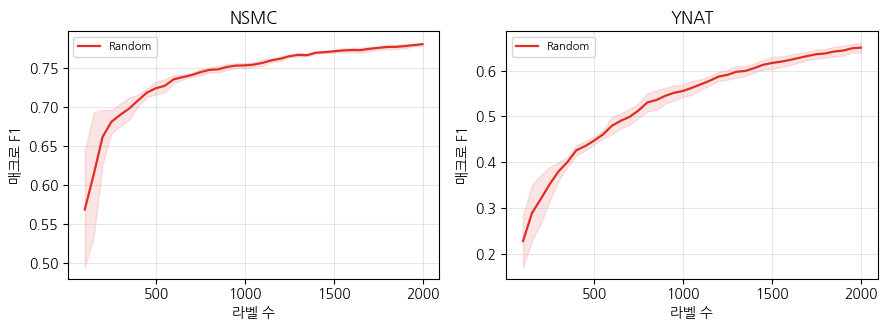

In [9]:
# ── 학습 곡선과 지표 ────
for name, r in res.items():
    for metric in ("acc", "f1"):
        print(name, LABEL[metric])
        print(summarize(r, metric).to_string(index=False))
    print(r.groupby("n_labeled")[["acc", "f1"]].mean().iloc[::10].round(4))

fig, axes = plt.subplots(1, 2, figsize=(9, 3.4))
for ax, (name, r) in zip(axes, res.items()):
    plot_curves(r, "f1", ax, name.upper())
fig.tight_layout()
fig.savefig("out/ch02_random_curve.png", dpi=200)

## 2.6 초기 라벨 크기와 질의 배치 크기의 영향

초기 라벨 {20, 100, 500}과 배치 크기 {10, 50, 200}의 격자를 NSMC에서 시드 3개로 돌린다. 계산량 때문에 시드를 줄였다. 초기 크기가 다르면 곡선의 시작점이 다르므로 모든 조합에 공통인 구간 [500, 2000]의 ALC를 비교한다. 측정점이 구간 경계와 맞지 않는 곳은 선형 보간한다.

In [10]:
# ── 초기 라벨 크기와 배치 크기 격자 ────
GRID_INIT, GRID_K = [20, 100, 500], [10, 50, 200]

def alc_window(n, m, lo, hi):
    g = np.arange(lo, hi + 1, 10)
    return alc(g, np.interp(g, n, m), hi)

nsmc = DATA["nsmc"]
oracle = make_sim_oracle(nsmc["y_pool"])
lo = max(GRID_INIT)
rows = []
for n_init in GRID_INIT:
    for k in GRID_K:
        for s in SEEDS[:3]:
            df, _ = run_loop(query_random, oracle, nsmc, s, n_init=n_init, k=k)
            rows.append(dict(n_init=n_init, k=k, seed=s, final=df.f1.iloc[-1],
                             ALC=alc_window(df.n_labeled.values, df.f1.values, lo, BUDGET)))
        print(f"n_init={n_init} 완료")
grid = pd.DataFrame(rows)
grid.to_csv("results/ch02_init_batch_grid.csv", index=False)
print(grid.groupby(["n_init", "k"])[["ALC", "final"]].agg(["mean", "std"]).round(4))

n_init=20 완료


n_init=20 완료


n_init=20 완료


n_init=100 완료


n_init=100 완료


n_init=100 완료


n_init=500 완료


n_init=500 완료


n_init=500 완료
               ALC           final        
              mean     std    mean     std
n_init k                                  
20     10   0.7633  0.0051  0.7817  0.0047
       50   0.7623  0.0031  0.7839  0.0039
       200  0.7603  0.0057  0.7844  0.0066
100    10   0.7590  0.0020  0.7816  0.0020
       50   0.7599  0.0023  0.7808  0.0025
       200  0.7606  0.0060  0.7804  0.0031
500    10   0.7619  0.0019  0.7836  0.0052
       50   0.7633  0.0024  0.7807  0.0066
       200  0.7633  0.0016  0.7818  0.0013


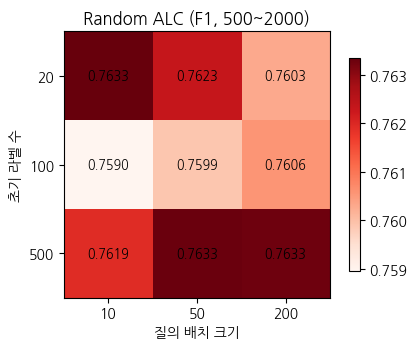

In [11]:
# ── 격자 히트맵 ────
table = grid.groupby(["n_init", "k"]).ALC.mean().unstack()
fig, ax = plt.subplots(figsize=(4.6, 3.6))
im = ax.imshow(table.values, cmap="Reds")
for i in range(table.shape[0]):
    for j in range(table.shape[1]):
        ax.text(j, i, f"{table.values[i, j]:.4f}", ha="center", va="center", fontsize=9)
ax.set(xticks=range(len(GRID_K)), xticklabels=GRID_K, yticks=range(len(GRID_INIT)), yticklabels=GRID_INIT,
       xlabel="질의 배치 크기", ylabel="초기 라벨 수", title=f"Random ALC (F1, {lo}~{BUDGET})")
fig.colorbar(im, ax=ax, shrink=0.8)
fig.tight_layout()
fig.savefig("out/ch02_init_batch_grid.png", dpi=200)